# 05 – Tổng hợp nhật ký thực nghiệm

In [2]:
# Colab: Runtime > Change runtime type > GPU (T4)
from google.colab import drive
drive.mount('/content/drive')
import sys
PROJECT = "/content/drive/MyDrive/FER2013_PyTorch"
sys.path.insert(0, PROJECT)
from common import *
print("Device:", DEV, "| torch", torch.__version__)

Mounted at /content/drive
Device: cpu | torch 2.14.1+cpu


In [3]:
import pandas as pd
rows = [json.loads(p.read_text()) for p in sorted(RUNS_DIR.glob('*/results.json'))]
cols = ['group','exp_name','model','bn','optimizer','lr','batch_size','aug','fc_drop','class_weight','label_smoothing',
        'params','best_epoch','epochs_run','train_acc_at_best','val_acc','test_acc','test_macro_f1','train_time_sec','note']
df = pd.DataFrame(rows)[cols].sort_values(['group','exp_name']).reset_index(drop=True)
df.to_csv(PROJECT+'/experiment_log.csv', index=False, encoding='utf-8-sig')
display(df.style.format({c:'{:.4f}' for c in ['train_acc_at_best','val_acc','test_acc','test_macro_f1']}))

,group,exp_name,model,bn,optimizer,lr,batch_size,aug,fc_drop,class_weight,label_smoothing,params,best_epoch,epochs_run,train_acc_at_best,val_acc,test_acc,test_macro_f1,train_time_sec,note
0,A,A_large,cnn_large,True,adam,0.001000,64,basic,0.500000,False,0.000000,20410439,52,60,0.7308,0.6668,0.6865,0.6554,1620.000000,
1,A,A_small,cnn_small,True,adam,0.001000,64,basic,0.500000,False,0.000000,10590535,57,60,0.7227,0.6843,0.7033,0.6720,844.000000,
2,A,A_vgg16_ft,vgg16_ft,True,adam,0.000100,64,basic,0.500000,False,0.000000,15779655,30,42,0.9478,0.7013,0.7058,0.7011,995.200000,"VGG16 ImageNet fine-tune, ảnh 64x64"
3,B,B_nobn,cnn_medium,False,adam,0.000100,64,basic,0.500000,False,0.000000,12101895,60,60,0.7400,0.6704,0.6904,0.6690,1044.600000,"không BN, lr thấp"
4,BASE,base,cnn_medium,True,adam,0.001000,64,basic,0.500000,False,0.000000,12103623,53,60,0.7490,0.6757,0.7027,0.6810,1199.700000,baseline
5,C,C_adam_1e-4,cnn_medium,True,adam,0.000100,64,basic,0.500000,False,0.000000,12103623,60,60,0.7854,0.6927,0.6994,0.6789,1126.600000,
6,C,C_adamw_cos,cnn_medium,True,adamw,0.001000,64,basic,0.500000,False,0.000000,12103623,52,60,0.7427,0.6902,0.7013,0.6720,1135.200000,
7,C,C_sgd_0.01,cnn_medium,True,sgd,0.010000,64,basic,0.500000,False,0.000000,12103623,57,60,0.7826,0.6924,0.7119,0.6855,1110.100000,
8,D,D_noaug,cnn_medium,True,adam,0.001000,64,none,0.500000,False,0.000000,12103623,41,53,0.9331,0.6562,0.6707,0.6577,950.100000,
9,D,D_strong,cnn_medium,True,adam,0.001000,64,strong,0.500000,False,0.000000,12103623,60,60,0.6755,0.6684,0.6843,0.6370,1393.100000,


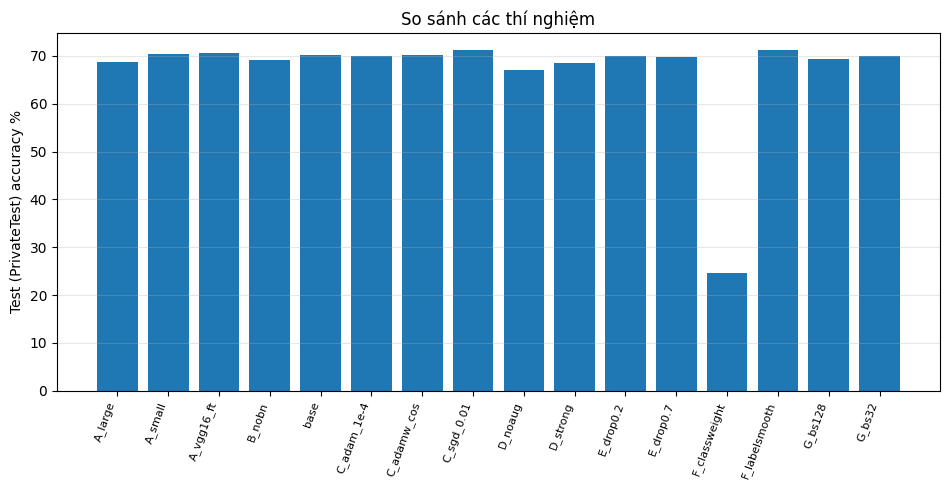

In [4]:
plt.figure(figsize=(max(8, len(df)*.6), 5)); plt.bar(df['exp_name'], df['test_acc']*100)
plt.xticks(rotation=70, ha='right', fontsize=8); plt.ylabel('Test (PrivateTest) accuracy %'); plt.grid(axis='y', alpha=.3)
plt.title('So sánh các thí nghiệm'); plt.tight_layout(); plt.savefig(PROJECT+'/compare_test_acc.png', dpi=130); plt.show()

## Recall từng lớp

In [5]:
rec = pd.DataFrame({r['exp_name']: r['per_class_recall'] for r in rows}).T
display(rec.style.format('{:.3f}').background_gradient(cmap='Blues', axis=None))

,Angry,Disgust,Fear,Happy,Sad,Surprise,Neutral
A_large,0.629,0.582,0.403,0.901,0.569,0.772,0.733
A_small,0.635,0.473,0.481,0.914,0.549,0.798,0.752
A_vgg16_ft,0.621,0.673,0.530,0.885,0.582,0.805,0.722
B_nobn,0.644,0.564,0.468,0.903,0.507,0.812,0.720
C_adam_1e-4,0.633,0.673,0.428,0.909,0.534,0.846,0.748
C_adamw_cos,0.625,0.564,0.456,0.902,0.576,0.834,0.728
C_sgd_0.01,0.654,0.564,0.432,0.915,0.623,0.856,0.711
D_noaug,0.587,0.655,0.477,0.863,0.535,0.803,0.671
D_strong,0.568,0.400,0.443,0.916,0.478,0.810,0.791
E_drop0.2,0.619,0.764,0.451,0.894,0.571,0.832,0.727
